# Chapter 2: Putting brakes on the model

*Regularisation · also searched as: L1 L2 regularization, ridge regression, lasso regression*

**By the end you can** say what a penalty trades for what, watch a brake calm a curve, see L1 switch
columns off, and name the brakes a tree has. All numbers here are invented.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11, "axes.titleweight": "bold"})
INK, VIOLET, ROSE, GREEN, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690"

def check(label, ok):
    """Print PASS or FAIL on one line, so a reader sees at a glance whether a step worked."""
    print(("PASS  " if ok else "FAIL  ") + label)

print("Charts and the check() helper are ready.")

Charts and the check() helper are ready.


## Predict first

A Kalpa store's weekly footfall for twelve weeks. Nine weeks teach the model and three are held out.
A curve with seven bends can pass through all nine teaching weeks. Will it predict the three held-out
weeks well?

In [2]:
import numpy as np, pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge, Lasso
# Invented: weekly footfall at one Kalpa store, in hundreds of visitors.
week = np.arange(1, 13)
footfall = np.array([42, 47, 55, 52, 60, 66, 63, 70, 74, 71, 78, 80])
held_out = np.isin(week, [4, 7, 10])
W_tr, y_tr = week[~held_out, None], footfall[~held_out]
W_ho, y_ho = week[held_out, None], footfall[held_out]

def brake(alpha, kind=Ridge):
    return make_pipeline(PolynomialFeatures(7, include_bias=False), StandardScaler(),
                         kind(alpha=alpha, max_iter=100000) if kind is Lasso else kind(alpha=alpha)).fit(W_tr, y_tr)

def rmse(m, W, y):
    return float(np.sqrt(np.mean((m.predict(W) - y) ** 2)))

free, braked = brake(1e-6), brake(10)
for name, m in [("No brake", free), ("Brake at alpha 10", braked)]:
    print(f"{name:18s} teaching-week error {rmse(m, W_tr, y_tr):5.2f}   held-out error {rmse(m, W_ho, y_ho):5.2f}")

No brake           teaching-week error  0.95   held-out error  5.28
Brake at alpha 10  teaching-week error  5.74   held-out error  2.90


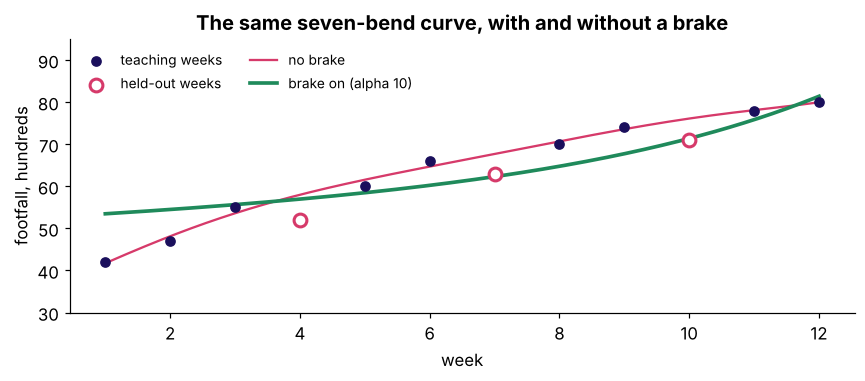

In [3]:
grid = np.linspace(1, 12, 200)[:, None]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(W_tr, y_tr, color=INK, zorder=3, label="teaching weeks")
ax.scatter(W_ho, y_ho, facecolors="white", edgecolors=ROSE, s=70, lw=2, zorder=3, label="held-out weeks")
ax.plot(grid, free.predict(grid), color=ROSE, label="no brake")
ax.plot(grid, braked.predict(grid), color=GREEN, lw=2.4, label="brake on (alpha 10)")
ax.set_ylim(30, 95); ax.set_xlabel("week"); ax.set_ylabel("footfall, hundreds")
ax.legend(frameon=False, ncol=2, fontsize=9); ax.set_title("The same seven-bend curve, with and without a brake")
plt.tight_layout(); plt.show()

## Turn the brake up slowly

The penalty adds the size of the coefficients to the error the model tries to shrink. A bigger
`alpha` makes large coefficients expensive, so the curve calms down.

 alpha  teaching_error  held_out_error  size_of_coefficients
  0.00            0.95            5.28                717.51
  0.00            0.99            5.19                 63.56
  0.01            1.10            5.04                 33.27
  0.10            1.46            4.83                 22.77
  1.00            2.65            3.88                 17.13
 10.00            5.74            2.90                  9.50
100.00            9.52            5.70                  4.11


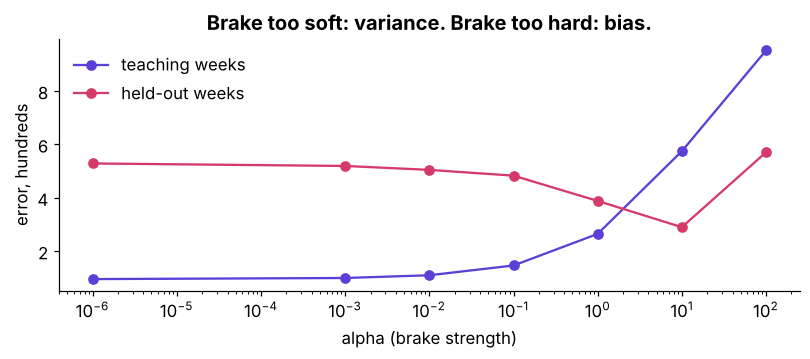

In [4]:
rows = []
for a in [1e-6, 1e-3, 1e-2, 0.1, 1, 10, 100]:
    m = brake(a)
    rows.append({"alpha": a, "teaching_error": rmse(m, W_tr, y_tr), "held_out_error": rmse(m, W_ho, y_ho),
                 "size_of_coefficients": float(np.abs(m[-1].coef_).sum())})
sweep = pd.DataFrame(rows)
print(sweep.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(sweep["alpha"], sweep["teaching_error"], "o-", color=VIOLET, label="teaching weeks")
ax.plot(sweep["alpha"], sweep["held_out_error"], "o-", color=ROSE, label="held-out weeks")
ax.set_xscale("log"); ax.set_xlabel("alpha (brake strength)"); ax.set_ylabel("error, hundreds")
ax.legend(frameon=False); ax.set_title("Brake too soft: variance. Brake too hard: bias.")
plt.tight_layout(); plt.show()

In [5]:
best = sweep.loc[sweep["held_out_error"].idxmin()]
check("a middle brake gives the lowest held-out error", 1e-6 < best["alpha"] < 100)
check("teaching error only rises as the brake tightens",
      bool((sweep["teaching_error"].diff().dropna() >= -1e-9).all()))

PASS  a middle brake gives the lowest held-out error
PASS  teaching error only rises as the brake tightens


## The formula, named last

```
ridge (L2):  minimise  misfit + alpha * (sum of squared coefficients)
lasso (L1):  minimise  misfit + alpha * (sum of absolute coefficients)
```

L2 shrinks every coefficient a little. L1 pushes the weakest ones to exactly zero, so it also picks
columns. In scikit-learn's `LogisticRegression` the knob is `C = 1 / alpha`: **a small C is a strong
brake**, the opposite of what the letter suggests.

In [6]:
lasso_rows = []
for a in [0.01, 0.1, 0.5, 1, 3]:
    m = brake(a, Lasso)
    lasso_rows.append({"alpha": a, "coefficients_kept": int((np.abs(m[-1].coef_) > 1e-6).sum()),
                       "of": 7, "held_out_error": rmse(m, W_ho, y_ho)})
lasso = pd.DataFrame(lasso_rows)
print(lasso.round(2).to_string(index=False))
check("L1 switches most of the seven bends off", lasso["coefficients_kept"].min() <= 2)

 alpha  coefficients_kept  of  held_out_error
  0.01                  3   7            5.09
  0.10                  2   7            4.82
  0.50                  2   7            3.95
  1.00                  1   7            3.70
  3.00                  1   7            3.65
PASS  L1 switches most of the seven bends off


## A tree's brakes have other names

A tree has no coefficients. Its brakes are `max_depth` (how many questions in a row) and
`min_samples_leaf` (how many customers a final answer must cover). Case 1 turns the first one.

## Carry this

| Rule | When it flips |
|---|---|
| A brake trades a little fit on the teaching rows for a lot of stability on new rows | when the model had no room to memorise: then the brake only adds bias |
| Choose the strength on held-out rows, never on the teaching rows | the teaching error always prefers no brake |
| L1 also chooses columns | when two columns move together it keeps one at random, so read its picks with care |

Why L1 lands exactly on zero is geometry, which belongs to the tentative IITGN faculty session.